In [ ]:
# Smishing and Suspicious SMS Detection
# UCI SMS and LSDST-2022 SMS Phishing datasets
# Huynh Cong Phap
#-----------------------


In [ ]:
!pip install numpy>=2.0 captum torchmetrics -q

In [ ]:
total_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Số tham số (Triệu): {total_params:.2f} M")

Số tham số (Triệu): 1.37 M


[INFO] Environment initialized on: cpu

 1. DATA PIPELINE & Table 1: Dataset Configurations


,Dataset,Original Labels,Positive Class,Negative Class,Total,Positive Rate,T_max
0,UCI SMS Spam,"ham, spam",spam,ham,5574,13.40%,39
1,LSDST-2022,"ham, spam, smishing","spam, smishing",ham,5971,18.87%,38



 2. EXPERIMENTS: Running with 5 Seeds for Robustness
Running base seed (42) for reference models...
Aggregating metrics over seeds [13, 21, 42, 87, 100]...
Evaluating DistilBERT Footprint/Latency (Table 3 Reference)...


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...


 3. TABLE 4: Ablation Study on LSDST-2022


,Configuration,Recall,F1,AP,Expected Cost (C_FN=5)
0,BiGRU + MeanPool + BCE,0.9204,0.9391,0.9858,99
1,BiGRU + MaskedPool + BCE,0.9204,0.9348,0.9793,101
2,BiGRU + MeanPool + WBCE,0.9558,0.9495,0.9870,63
3,BiGRU + MaskedPool + WBCE (Proposed),0.9602,0.9394,0.9823,64



 4. TABLE 5: Cross-Domain Evaluation (Target Held-Out Split)


,Train,Test,Model,Recall,F1,AP
0,UCI,LSDST,TF-IDF + LR,0.9690,0.9648,0.9945
1,UCI,LSDST,BiGRU+Masked+WBCE,0.9867,0.9633,0.9950
2,LSDST,UCI,TF-IDF + LR,0.9664,0.9664,0.9974
3,LSDST,UCI,BiGRU+Masked+WBCE,0.9799,0.9733,0.9918



 5. FIGURE 1: Threshold Sensitivity vs Expected Cost


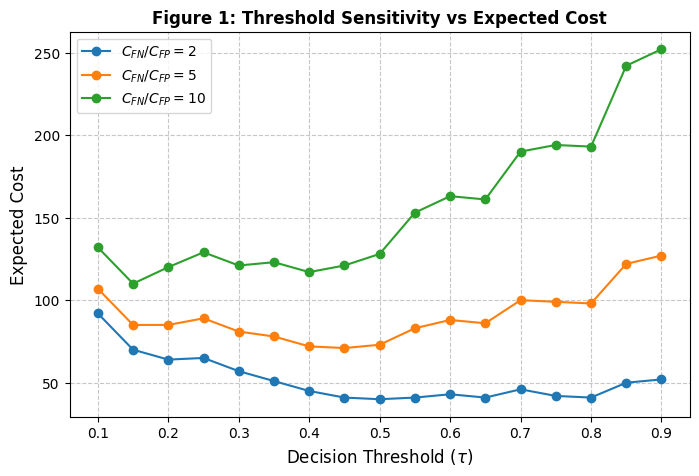


 6. OBFUSCATION STRESS TEST (Honesty in Limitations)


,Model,Original Recall,Adversarial Recall,Recall Drop (%)
0,TF-IDF + LR,0.946903,0.924779,2.21%
1,BiGRU+MaskedPool+WBCE,0.951327,0.911504,3.98%



[INFO] Pipeline completed successfully. All assets ready for manuscript.


In [ ]:
import os
import sys
import time
import tempfile
import joblib
import random
import csv
import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
import re
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 0. SETUP, INSTALLATIONS & DIRECTORIES
# ==========================================
os.makedirs("results/tables", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

try:
    from transformers import DistilBertTokenizer, DistilBertForSequenceClassification
except ImportError:
    print("[INFO] Installing required packages...")
    os.system('pip install transformers torchmetrics -q')
    from transformers import DistilBertTokenizer, DistilBertForSequenceClassification

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[INFO] Environment initialized on: {device}")

SEEDS = [13, 21, 42, 87, 100]

# ==========================================
# 1. HELPER FUNCTIONS (Latency & Footprint)
# ==========================================
def serialized_size_sklearn(obj):
    path = tempfile.NamedTemporaryFile(delete=False, suffix=".joblib").name
    joblib.dump(obj, path)
    size_mb = os.path.getsize(path) / (1024 ** 2)
    os.remove(path)
    return size_mb

def serialized_size_torch_with_vocab(model, vocab):
    path = tempfile.NamedTemporaryFile(delete=False, suffix=".pt").name
    torch.save({'state_dict': model.state_dict(), 'word2idx': vocab}, path)
    size_mb = os.path.getsize(path) / (1024 ** 2)
    os.remove(path)
    return size_mb

def measure_torch_latency(model, dataloader, n_warmup=1):
    model.eval()
    with torch.no_grad():
        for _ in range(n_warmup):
            for x, _ in dataloader:
                _ = model(x.to(device))
                break
        n_samples = 0
        start = time.perf_counter()
        for x, _ in dataloader:
            _ = model(x.to(device))
            n_samples += x.size(0)
        elapsed = time.perf_counter() - start
    return (1000 * elapsed) / n_samples if n_samples > 0 else 0

def measure_bert_latency(model, dataloader, n_warmup=1):
    model.eval()
    with torch.no_grad():
        for _ in range(n_warmup):
            for ids, mask in dataloader:
                _ = model(ids.to(device), attention_mask=mask.to(device))
                break
        n_samples = 0
        start = time.perf_counter()
        for ids, mask in dataloader:
            _ = model(ids.to(device), attention_mask=mask.to(device))
            n_samples += ids.size(0)
        elapsed = time.perf_counter() - start
    return (1000 * elapsed) / n_samples if n_samples > 0 else 0

def measure_sklearn_latency(vectorizer, model, texts):
    start = time.perf_counter()
    _ = model.predict_proba(vectorizer.transform(texts))
    elapsed = time.perf_counter() - start
    return (1000 * elapsed) / len(texts)

def eval_metrics(y_true, y_prob):
    y_pred = (y_prob > 0.5).astype(int)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc_a = roc_auc_score(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)
    return prec, rec, f1, roc_a, ap

def compute_tmax(texts, percentile=95):
    lengths = [len(t.split()) for t in texts]
    return int(np.percentile(lengths, percentile))

# ==========================================
# 2. DATA PIPELINE & TABLE 1
# ==========================================
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '<url>', text)
    text = re.sub(r'\b\d{2,}\b', '<num>', text)
    text = re.sub(r'([!?.,])', r' \1 ', text)
    return re.sub(r'\s+', ' ', text).strip()

print("\n" + "="*85)
print(" 1. DATA PIPELINE & Table 1: Dataset Configurations")
print("="*85)

# UCI
url_uci = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df_uci = pd.read_csv(url_uci, sep='\t', names=['label', 'text'], quoting=csv.QUOTE_NONE).dropna()
df_uci['clean_text'] = df_uci['text'].apply(clean_text)
# UCI: ham=0, spam=1
df_uci['label_mapped'] = df_uci['label'].map({'ham': 0, 'spam': 1})
tmax_uci = compute_tmax(df_uci['clean_text'].values)

# LSDST-2022
raw_url_lsdst = "https://raw.githubusercontent.com/hcphap/Smishing-Dataset/main/LSDST-2022.csv.csv"
df_lsdst = pd.read_csv(raw_url_lsdst, dtype=str)
c_text = [c for c in df_lsdst.columns if 'text' in c.lower() or 'message' in c.lower()][0]
c_label = [c for c in df_lsdst.columns if 'label' in c.lower() or 'class' in c.lower()][0]
df_lsdst = df_lsdst.rename(columns={c_text: 'text', c_label: 'label'}).dropna(subset=['text', 'label'])
df_lsdst['label'] = df_lsdst['label'].astype(str).str.strip().str.lower()
df_lsdst = df_lsdst[df_lsdst['label'].isin(['ham', 'spam', 'smishing'])].copy()
df_lsdst['clean_text'] = df_lsdst['text'].apply(clean_text)

# CROSS-DOMAIN: Cả spam và smishing đều quy về 1 (Threat)
df_lsdst['label_mapped'] = df_lsdst['label'].map({'ham': 0, 'spam': 1, 'smishing': 1})
tmax_lsdst = compute_tmax(df_lsdst['clean_text'].values)

table1 = [
    {'Dataset': 'UCI SMS Spam', 'Original Labels': 'ham, spam', 'Positive Class': 'spam', 'Negative Class': 'ham', 'Total': len(df_uci), 'Positive Rate': f"{df_uci['label_mapped'].mean():.2%}", 'T_max': tmax_uci},
    {'Dataset': 'LSDST-2022', 'Original Labels': 'ham, spam, smishing', 'Positive Class': 'spam, smishing', 'Negative Class': 'ham', 'Total': len(df_lsdst), 'Positive Rate': f"{df_lsdst['label_mapped'].mean():.2%}", 'T_max': tmax_lsdst}
]
df_table1 = pd.DataFrame(table1)
df_table1.to_csv("results/tables/Table1_Dataset_Config.csv", index=False)
display(df_table1)

# ==========================================
# 3. NEURAL ARCHITECTURES
# ==========================================
class CNN1D(nn.Module):
    def __init__(self, vocab_size, embed_dim=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.conv = nn.Conv1d(embed_dim, 128, kernel_size=3, padding=1)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.fc = nn.Linear(128, 1)
    def forward(self, x):
        return torch.sigmoid(self.fc(self.pool(torch.relu(self.conv(self.emb(x).permute(0, 2, 1)))).squeeze(-1)))

class BiLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, 128, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(256, 1)
    def forward(self, x):
        _, (hidden, _) = self.lstm(self.emb(x))
        return torch.sigmoid(self.fc(torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)))

class BiGRUMeanPool(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.bigru = nn.GRU(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim * 2, 1)
    def forward(self, x):
        gru_out, _ = self.bigru(self.emb(x))
        return torch.sigmoid(self.fc(self.dropout(torch.mean(gru_out, dim=1))))

class MaskedBiGRU(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.bigru = nn.GRU(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim * 2, 1)
    def forward(self, x):
        lengths = (x != 0).sum(dim=1).cpu()
        lengths = torch.clamp(lengths, min=1)

        emb = self.emb(x)
        packed = pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        packed_out, _ = self.bigru(packed)
        gru_out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=x.size(1))

        mask = (x != 0).float().unsqueeze(-1)
        valid_lens = torch.clamp(torch.sum(mask, dim=1), min=1e-9)
        pooled = torch.sum(gru_out * mask, dim=1) / valid_lens
        return torch.sigmoid(self.fc(self.dropout(pooled)))

# ==========================================
# 4. EXPERIMENTAL PIPELINE (MULTIPLE SEEDS)
# ==========================================
print("\n" + "="*85)
print(f" 2. EXPERIMENTS: Running with {len(SEEDS)} Seeds for Robustness")
print("="*85)

class TxtData(Dataset):
    def __init__(self, X, y): self.X, self.y = torch.tensor(X, dtype=torch.long), torch.tensor(y, dtype=torch.float32)
    def __len__(self): return len(self.y)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

def run_experiment_seed(df_full, dataset_name, seed):
    set_seed(seed)

    df_tr, df_te = train_test_split(df_full, test_size=0.2, stratify=df_full['label_mapped'], random_state=seed)
    X_tr, y_tr = df_tr['clean_text'].values, df_tr['label_mapped'].values
    X_te, y_te = df_te['clean_text'].values, df_te['label_mapped'].values
    t_max = compute_tmax(X_tr)

    # TF-IDF
    vectorizer = TfidfVectorizer(max_features=5000)
    lr_model = LogisticRegression(class_weight='balanced', max_iter=1000)
    lr_model.fit(vectorizer.fit_transform(X_tr), y_tr)
    lr_probs = lr_model.predict_proba(vectorizer.transform(X_te))[:, 1]

    tfidf_metrics = eval_metrics(y_te, lr_probs)
    tfidf_lat = measure_sklearn_latency(vectorizer, lr_model, X_te)
    tfidf_mem = serialized_size_sklearn((vectorizer, lr_model))
    tfidf_params = len(vectorizer.vocabulary_)

    # DL Prep
    vocab = Counter(" ".join(X_tr).split())
    w2i = {'<PAD>': 0, '<UNK>': 1}
    for word, _ in vocab.most_common(9998): w2i[word] = len(w2i)
    def encode(texts): return np.array([[w2i.get(w, 1) for w in t.split()][:t_max] + [0]*max(0, t_max-len(t.split())) for t in texts])

    tr_dl = DataLoader(TxtData(encode(X_tr), y_tr), batch_size=64, shuffle=True)
    te_dl = DataLoader(TxtData(encode(X_te), y_te), batch_size=64, shuffle=False)

    def train_dl(model, use_wbce=False):
        opt = optim.Adam(model.parameters(), lr=1e-3)
        model.train()
        w1, w0 = len(y_tr)/(2*sum(y_tr)), len(y_tr)/(2*(len(y_tr)-sum(y_tr)))
        for _ in range(3):
            for x, y in tr_dl:
                opt.zero_grad()
                preds = model(x.to(device)).squeeze(-1)
                if use_wbce:
                    preds_c = torch.clamp(preds, 1e-7, 1-1e-7)
                    loss = - (w1 * y.to(device) * torch.log(preds_c) + w0 * (1 - y.to(device)) * torch.log(1 - preds_c)).mean()
                else: loss = nn.BCELoss()(preds, y.to(device))
                loss.backward()
                opt.step()
        model.eval()
        probs = []
        with torch.no_grad():
            for x, _ in te_dl: probs.extend(model(x.to(device)).squeeze(-1).cpu().numpy())
        metrics = eval_metrics(y_te, np.array(probs))
        lat = measure_torch_latency(model, te_dl)
        mem = serialized_size_torch_with_vocab(model, w2i)
        params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        return metrics, params, mem, lat, model, np.array(probs)

    cnn_res = train_dl(CNN1D(len(w2i)).to(device))
    bilstm_res = train_dl(BiLSTM(len(w2i)).to(device))
    bigru_res = train_dl(MaskedBiGRU(len(w2i)).to(device), use_wbce=True)

    return {
        'TF-IDF + LR': (tfidf_metrics, tfidf_params, tfidf_mem, tfidf_lat, vectorizer, lr_model),
        'CNN-1D': cnn_res,
        'BiLSTM': bilstm_res,
        'BiGRU+MaskedPool+WBCE': bigru_res,
        'Data_Test': (X_te, y_te),
        'df_te': df_te,
        'w2i': w2i,
        'tmax': t_max
    }

# Run for 1 base seed (42) to keep models for Deployability Table & Cross-Domain
print("Running base seed (42) for reference models...")
res_uci_base = run_experiment_seed(df_uci, "UCI", 42)
res_lsdst_base = run_experiment_seed(df_lsdst, "LSDST", 42)

# Aggregate Table 2 (Performance) & Table 3 (Footprint) over SEEDS
print(f"Aggregating metrics over seeds {SEEDS}...")
table2_data = []
table3_data = []

def agg_metrics(df, d_name, base_res):
    models = ['TF-IDF + LR', 'CNN-1D', 'BiLSTM', 'BiGRU+MaskedPool+WBCE']
    all_res = {m: [] for m in models}

    for s in SEEDS:
        res = run_experiment_seed(df, d_name, s)
        for m in models: all_res[m].append(res[m][0])

    for m in models:
        arr = np.array(all_res[m])
        means = arr.mean(axis=0)
        stds = arr.std(axis=0)
        table2_data.append({
            'Dataset': d_name, 'Model': m,
            'Precision': f"{means[0]:.3f} ± {stds[0]:.3f}",
            'Recall': f"{means[1]:.3f} ± {stds[1]:.3f}",
            'F1': f"{means[2]:.3f} ± {stds[2]:.3f}",
            'ROC-AUC': f"{means[3]:.3f} ± {stds[3]:.3f}",
            'AP': f"{means[4]:.3f} ± {stds[4]:.3f}"
        })

        # Only populate deployability table once using the base run (LSDST)
        if d_name == 'LSDST':
            vocab_dim = f"{base_res[m][1]:,}" if 'TF-IDF' in m else f"{len(base_res['w2i']):,} x 128"
            table3_data.append({
                'Model': m, 'Params/Features': f"{base_res[m][1]:,}", 'Vocab/Feature Dim': vocab_dim,
                'Serialized Footprint (MB)': f"{base_res[m][2]:.2f}",
                'Model-only CPU Latency (ms)': f"{base_res[m][3]:.2f}"
            })

agg_metrics(df_uci, "UCI", res_uci_base)
agg_metrics(df_lsdst, "LSDST", res_lsdst_base)

# DistilBERT Reference (Only for Table 3)
print("Evaluating DistilBERT Footprint/Latency (Table 3 Reference)...")
set_seed(42)
bert_tok = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')
bert_mod = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2).to(device)
X_te_lsdst = res_lsdst_base['Data_Test'][0]
b_te_enc = bert_tok(X_te_lsdst.tolist(), truncation=True, padding=True, max_length=res_lsdst_base['tmax'], return_tensors='pt')
b_te_dl = DataLoader(torch.utils.data.TensorDataset(b_te_enc['input_ids'], b_te_enc['attention_mask']), batch_size=32, shuffle=False)

bert_lat = measure_bert_latency(bert_mod, b_te_dl)
bert_mem = serialized_size_torch_with_vocab(bert_mod, bert_tok.vocab)
bert_params = sum(p.numel() for p in bert_mod.parameters() if p.requires_grad)

table3_data.append({
    'Model': 'DistilBERT (Reference)', 'Params/Features': f"{bert_params:,}", 'Vocab/Feature Dim': f"{bert_tok.vocab_size:,} x 768",
    'Serialized Footprint (MB)': f"{bert_mem:.2f}", 'Model-only CPU Latency (ms)': f"{bert_lat:.2f}"
})

df_t2 = pd.DataFrame(table2_data)
df_t2.to_csv("results/tables/Table2_Performance.csv", index=False)
print("\n--- TABLE 2: In-Domain Classification Performance ---")
display(df_t2)

df_t3 = pd.DataFrame(table3_data)
df_t3.to_csv("results/tables/Table3_Deployability.csv", index=False)
print("\n--- TABLE 3: Deployment-Oriented Footprint and CPU Latency ---")
display(df_t3)

# Figure: Footprint vs Latency
fig, ax1 = plt.subplots(figsize=(10, 6))
models_plot = df_t3['Model'].tolist()
footprint = df_t3['Serialized Footprint (MB)'].astype(float).tolist()
latency = df_t3['Model-only CPU Latency (ms)'].astype(float).tolist()

x = np.arange(len(models_plot))
width = 0.35

ax1.bar(x - width/2, footprint, width, label='Serialized Footprint (MB)', color='#1f77b4')
ax1.set_ylabel('Footprint (MB)', color='#1f77b4', fontweight='bold')
ax1.set_yscale('log')
ax1.set_xticks(x)
ax1.set_xticklabels(models_plot, rotation=15, ha='right')

ax2 = ax1.twinx()
ax2.bar(x + width/2, latency, width, label='Model-only Latency (ms)', color='#d62728')
ax2.set_ylabel('Latency (ms)', color='#d62728', fontweight='bold')

plt.title('Figure: Serialized Footprint and CPU Latency', fontweight='bold')
fig.tight_layout()
plt.savefig("results/figures/Figure2_Footprint_Latency.pdf")
plt.close()

# ==========================================
# 5. TABLE 4: STRICT ABLATION STUDY
# ==========================================
print("\n" + "="*85)
print(" 3. TABLE 4: Ablation Study on LSDST-2022")
print("="*85)

def run_ablation():
    set_seed(42)
    df_tr_ab, df_te_ab = train_test_split(df_lsdst, test_size=0.2, stratify=df_lsdst['label_mapped'], random_state=42)
    X_tr_l, y_tr_l = df_tr_ab['clean_text'].values, df_tr_ab['label_mapped'].values
    X_te_l, y_te_l = df_te_ab['clean_text'].values, df_te_ab['label_mapped'].values

    tmax_ab = compute_tmax(X_tr_l)
    vocab = Counter(" ".join(X_tr_l).split())
    w2i_ab = {'<PAD>': 0, '<UNK>': 1}
    for word, _ in vocab.most_common(9998): w2i_ab[word] = len(w2i_ab)

    def enc(texts): return np.array([[w2i_ab.get(w, 1) for w in t.split()][:tmax_ab] + [0]*max(0, tmax_ab-len(t.split())) for t in texts])
    tr_dl_ab = DataLoader(TxtData(enc(X_tr_l), y_tr_l), batch_size=64, shuffle=True)
    te_dl_ab = DataLoader(TxtData(enc(X_te_l), y_te_l), batch_size=64, shuffle=False)

    w1, w0 = len(y_tr_l)/(2*sum(y_tr_l)), len(y_tr_l)/(2*(len(y_tr_l)-sum(y_tr_l)))

    def run_abl_variant(model, use_wbce, name):
        set_seed(42)
        opt = optim.Adam(model.parameters(), lr=1e-3)
        model.train()
        for _ in range(3):
            for x, y in tr_dl_ab:
                opt.zero_grad()
                preds = model(x.to(device)).squeeze(-1)
                if use_wbce:
                    p_c = torch.clamp(preds, 1e-7, 1-1e-7)
                    loss = - (w1 * y.to(device) * torch.log(p_c) + w0 * (1 - y.to(device)) * torch.log(1 - p_c)).mean()
                else: loss = nn.BCELoss()(preds, y.to(device))
                loss.backward()
                opt.step()
        model.eval()
        probs = []
        with torch.no_grad():
            for x, _ in te_dl_ab: probs.extend(model(x.to(device)).squeeze(-1).cpu().numpy())
        _, r, f, _, ap = eval_metrics(y_te_l, np.array(probs))

        y_pred = (np.array(probs) >= 0.5).astype(int)
        _, fp, fn, _ = confusion_matrix(y_te_l, y_pred).ravel()
        return {'Configuration': name, 'Recall': f"{r:.4f}", 'F1': f"{f:.4f}", 'AP': f"{ap:.4f}", 'Expected Cost (C_FN=5)': (5*fn + 1*fp)}

    ab_res = [
        run_abl_variant(BiGRUMeanPool(len(w2i_ab)).to(device), False, "BiGRU + MeanPool + BCE"),
        run_abl_variant(MaskedBiGRU(len(w2i_ab)).to(device), False, "BiGRU + MaskedPool + BCE"),
        run_abl_variant(BiGRUMeanPool(len(w2i_ab)).to(device), True, "BiGRU + MeanPool + WBCE"),
        run_abl_variant(MaskedBiGRU(len(w2i_ab)).to(device), True, "BiGRU + MaskedPool + WBCE (Proposed)")
    ]
    return ab_res

df_t4 = pd.DataFrame(run_ablation())
df_t4.to_csv("results/tables/Table4_Ablation.csv", index=False)
display(df_t4)

# ==========================================
# 6. TABLE 5: CROSS-DOMAIN
# ==========================================
print("\n" + "="*85)
print(" 4. TABLE 5: Cross-Domain Evaluation (Target Held-Out Split)")
print("="*85)

def eval_cross(df_tgt_te, vec_src, lr_src, w2i_src, model_src, tmax_src):
    lr_probs = lr_src.predict_proba(vec_src.transform(df_tgt_te['clean_text'].values))[:, 1]
    _, r_t, f_t, _, ap_t = eval_metrics(df_tgt_te['label_mapped'].values, lr_probs)

    def enc(t): return np.array([[w2i_src.get(w, 1) for w in t_.split()][:tmax_src] + [0]*max(0, tmax_src-len(t_.split())) for t_ in t])
    te_dl = DataLoader(torch.utils.data.TensorDataset(torch.tensor(enc(df_tgt_te['clean_text'].values), dtype=torch.long)), batch_size=64, shuffle=False)

    model_src.eval()
    bg_probs = []
    with torch.no_grad():
        for x in te_dl: bg_probs.extend(model_src(x[0].to(device)).squeeze(-1).cpu().numpy())
    _, r_b, f_b, _, ap_b = eval_metrics(df_tgt_te['label_mapped'].values, np.array(bg_probs))
    return r_t, f_t, ap_t, r_b, f_b, ap_b

cross_data = []
# UCI -> LSDST (Test on LSDST Held-out split)
rt, ft, apt, rb, fb, apb = eval_cross(res_lsdst_base['df_te'], res_uci_base['TF-IDF + LR'][4], res_uci_base['TF-IDF + LR'][5], res_uci_base['w2i'], res_uci_base['BiGRU+MaskedPool+WBCE'][4], res_uci_base['tmax'])
cross_data.extend([{'Train': 'UCI', 'Test': 'LSDST', 'Model': 'TF-IDF + LR', 'Recall': f"{rt:.4f}", 'F1': f"{ft:.4f}", 'AP': f"{apt:.4f}"},
                   {'Train': 'UCI', 'Test': 'LSDST', 'Model': 'BiGRU+Masked+WBCE', 'Recall': f"{rb:.4f}", 'F1': f"{fb:.4f}", 'AP': f"{apb:.4f}"}])

# LSDST -> UCI (Test on UCI Held-out split)
rt, ft, apt, rb, fb, apb = eval_cross(res_uci_base['df_te'], res_lsdst_base['TF-IDF + LR'][4], res_lsdst_base['TF-IDF + LR'][5], res_lsdst_base['w2i'], res_lsdst_base['BiGRU+MaskedPool+WBCE'][4], res_lsdst_base['tmax'])
cross_data.extend([{'Train': 'LSDST', 'Test': 'UCI', 'Model': 'TF-IDF + LR', 'Recall': f"{rt:.4f}", 'F1': f"{ft:.4f}", 'AP': f"{apt:.4f}"},
                   {'Train': 'LSDST', 'Test': 'UCI', 'Model': 'BiGRU+Masked+WBCE', 'Recall': f"{rb:.4f}", 'F1': f"{fb:.4f}", 'AP': f"{apb:.4f}"}])

df_t5 = pd.DataFrame(cross_data)
df_t5.to_csv("results/tables/Table5_CrossDomain.csv", index=False)
display(df_t5)

# ==========================================
# 7. FIGURE: THRESHOLD SENSITIVITY
# ==========================================
print("\n" + "="*85)
print(" 5. FIGURE: Threshold Sensitivity vs Expected Cost")
print("="*85)

bg_probs_lsdst_base = res_lsdst_base['BiGRU+MaskedPool+WBCE'][5]
y_te_lsdst_base = res_lsdst_base['Data_Test'][1]

thresholds = np.arange(0.1, 0.95, 0.05)
cost_ratios = [2, 5, 10]
all_costs = {cr: [] for cr in cost_ratios}
opt_table = []

for tau in thresholds:
    y_pred_tau = (bg_probs_lsdst_base >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te_lsdst_base, y_pred_tau).ravel()
    for cr in cost_ratios: all_costs[cr].append((cr * fn) + (1 * fp))

for cr in cost_ratios:
    best_idx = np.argmin(all_costs[cr])
    opt_tau = thresholds[best_idx]
    opt_table.append({'Cost Ratio': cr, 'Optimal Tau': f"{opt_tau:.2f}", 'Min Expected Cost': int(all_costs[cr][best_idx])})

df_opt = pd.DataFrame(opt_table)
df_opt.to_csv("results/tables/Optimal_Thresholds.csv", index=False)

plt.figure(figsize=(8, 5))
for cr in cost_ratios:
    plt.plot(thresholds, all_costs[cr], marker='o', label=f'$C_{{FN}}/C_{{FP}} = {cr}$')
plt.xlabel(r'Decision Threshold ($\tau$)', fontsize=12)
plt.ylabel('Expected Cost', fontsize=12)
plt.title('Figure 1: Threshold Sensitivity vs Expected Cost', fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig("results/figures/Figure1_Threshold_Cost_Curve.pdf", bbox_inches="tight")
plt.show()

# ==========================================
# 8. OBFUSCATION STRESS TEST (Limitation)
# ==========================================
print("\n" + "="*85)
print(" 6. OBFUSCATION STRESS TEST (Honesty in Limitations)")
print("="*85)
def simulate_evasion(text):
    sub = {'a': '@', 'e': '3', 'i': '1', 'o': '0'}
    return " ".join([w.translate(str.maketrans(sub)) if len(w)>=4 and np.random.rand()>0.4 else w for w in text.split()])

pos_mask = (y_te_lsdst_base == 1)
X_test_pos = res_lsdst_base['df_te']['clean_text'].values[pos_mask]
y_test_pos = y_te_lsdst_base[pos_mask]
X_adv = np.array([simulate_evasion(t) for t in X_test_pos])

lr_lsdst = res_lsdst_base['TF-IDF + LR'][5]
vec_lsdst = res_lsdst_base['TF-IDF + LR'][4]
bg_mod_lsdst = res_lsdst_base['BiGRU+MaskedPool+WBCE'][4]
w2i_lsdst = res_lsdst_base['w2i']
tmax_lsdst = res_lsdst_base['tmax']

# Test TF-IDF
lr_rec_adv = recall_score(y_test_pos, (lr_lsdst.predict_proba(vec_lsdst.transform(X_adv))[:, 1] > 0.5).astype(int))
lr_rec_orig = recall_score(y_test_pos, (lr_lsdst.predict_proba(vec_lsdst.transform(X_test_pos))[:, 1] > 0.5).astype(int))

# Test BiGRU
def enc(t): return np.array([[w2i_lsdst.get(w, 1) for w in t_.split()][:tmax_lsdst] + [0]*max(0, tmax_lsdst-len(t_.split())) for t_ in t])
adv_dl = DataLoader(torch.utils.data.TensorDataset(torch.tensor(enc(X_adv), dtype=torch.long)), batch_size=64)
bg_probs_adv = []
bg_mod_lsdst.eval()
with torch.no_grad():
    for x in adv_dl: bg_probs_adv.extend(bg_mod_lsdst(x[0].to(device)).squeeze(-1).cpu().numpy())
bg_rec_adv = recall_score(y_test_pos, (np.array(bg_probs_adv) > 0.5).astype(int))
bg_rec_orig = recall_score(y_test_pos, (np.array(bg_probs_lsdst_base)[pos_mask] > 0.5).astype(int))

df_obf = pd.DataFrame({
    'Model': ['TF-IDF + LR', 'BiGRU+MaskedPool+WBCE'],
    'Original Recall': [lr_rec_orig, bg_rec_orig],
    'Adversarial Recall': [lr_rec_adv, bg_rec_adv],
    'Recall Drop (%)': [f"{(lr_rec_orig - lr_rec_adv)*100:.2f}%", f"{(bg_rec_orig - bg_rec_adv)*100:.2f}%"]
})
df_obf.to_csv("results/tables/Obfuscation_Limitation.csv", index=False)
display(df_obf)
print("\n[INFO] Pipeline completed successfully. All assets ready for manuscript.")

# New Section